Indicidual pulse plots

In [1]:
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Define variables:
theta = 0
tlist = np.linspace(0, 10, 1500)

#Hilbert space dimension:
N = 2

#Constants:
w = 1
gamma = 1
A = [np.pi/3,np.pi]
t0 = 2
sig = 0.2

#Creatrion/annihilation operator:
sigma = qt.destroy(N)
sigma_dag = sigma.dag()


#Define a dictionary for QuTiP to interpret the time dependence of the gaussian function.
#Gaussian function to model laser pulse: 
def gaussian(t,args):
    
    a = args["a"]
    t0 = args["t0"]
    sig = args["sig"]

    return (a / (np.sqrt(2 * np.pi) * sig)*np.exp(-((t - t0)**2) / (2 * sig**2)))

#Operators:
H0 = w*sigma_dag*sigma
H1 = (sigma + sigma_dag)/2

#Use a nested list so QuTiP evaluates the time dependence itself (cannot use a list of values).
#This is how QuTiP interprets the desired hamiltonian.
Ham = [H0,[H1,gaussian]]

#Collapse operators:
c_ops = [np.sqrt(gamma) * sigma] 


#Ground state:
ground = qt.basis(2,0) * qt.basis(2,0).dag() #Evolved state


rho_list = []
#Initial conditions are still important as the comparison of theta is still needed


x = np.sin(theta)
y = 0
z = np.cos(theta)

rho = 0.5 * (
    qt.qeye(2)
    + x * qt.sigmax()
    + y * qt.sigmay()
    + z * qt.sigmaz())



In [3]:
#Solve master equation:
results = []

for a in A:
    args = {"a": a, "t0": t0, "sig": sig} #Define here so one A value is passed through.
    
    results.append(qt.mesolve(Ham,rho,tlist,c_ops, 
            args=args, options={"max_step": sig/10}))#Make step small for small pulses.
    
all_rho_t = [res.states for res in results] #Gives a list of all rho(t), for different pulse areas.

In [4]:
#Calculate the trace distances to plot:
Dist = []


for rho_t in all_rho_t: #Loops over A   
    D_t = [qt.tracedist(rho, ground) for rho in rho_t]
    Dist.append(D_t)

Dist = np.array(Dist)

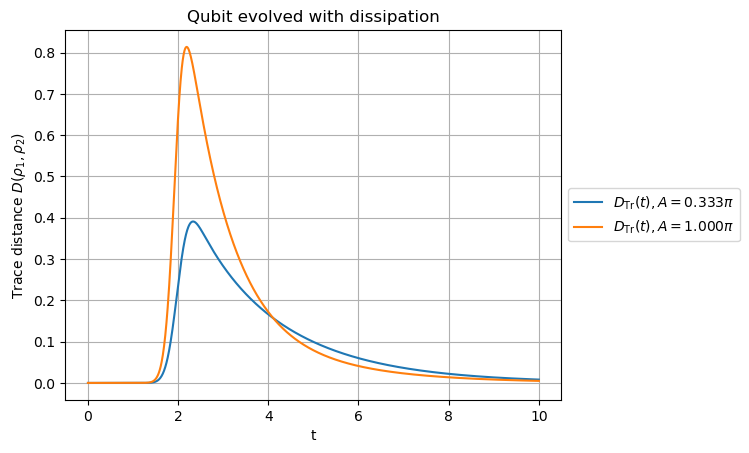

In [5]:
fig, ax = plt.subplots()



ax.plot(tlist, Dist[0],label=rf"$D_{{\rm Tr}}(t), A={A[0]/np.pi:.3f}\pi$")

ax.plot(tlist, Dist[1], label=rf"$D_{{\rm Tr}}(t), A={A[1]/np.pi:.3f}\pi$")

ax.set_title('Qubit evolved with dissipation')
ax.set_xlabel('t')
ax.set_ylabel("Trace distance $D(\\rho_1, \\rho_2)$")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid(True)

In [6]:
#Define list for the maximum Distance index:
max_vals = []

#Loop over all A values:
for i in range(len(A)):
    max_index = np.argmax(Dist[i]) #Index of max point

    max_vals.append(Dist[i][max_index]) #Add max value to list.